Реализовать алгоритм имитации отжига для задачи коммивояжера.  

Привести статистические результаты для экспериментов и сравнение с другими алгоритмами и/или оценками на оптимальное значение целевой функции.

Решая задачу **TSP** мы имеем $n$ городов и матрицу расстояний $d_{ij}$. Нам нужно пройти через **все** города ровно по одному разу, вернуться в исходный город и минимизировать суммарную длину маршрута.  

Длеать будем это с помощью **алгоритма имитации отжига**. Для сравнения будем использовать алгоритм ближайшего соседа, "окрестность 2-замена", а также известные оптимальные значения тестовых задач.  

воспользуемся симметричными тестами ($c_{ij} = c_{ji}$) (eil51 (51 город), berlin52 (52 города), st70 (70 городов)). Их известные оптимумы:  

$$\begin{cases} eil51 \rightarrow 426 \\ berlin52 \rightarrow 7542 \\ st70 \rightarrow 675 \end{cases}$$

(https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSP-BEST.html)



Загрузим данные  

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import tsplib95

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

TESTS = ["eil51", "berlin52", "st70"]
OPTIMUM = {"eil51": 426, "berlin52": 7542, "st70": 675}
BASE_URL = (
    "https://raw.githubusercontent.com/"
    "mastqe/tsplib/refs/heads/master"
)

problems = {}

for name in TESTS:
    path = DATA_DIR / f"{name}.tsp"

    if not path.exists():
        urlretrieve(f"{BASE_URL}/{name}.tsp", path)

    problems[name] = tsplib95.load(str(path))

    print(f"{name}: {problems[name].dimension} городов")


instances = {}
for name, problem in problems.items():
    nodes = list(problem.get_nodes())
    matrix = [[int(problem.get_weight(i, j)) for j in nodes] for i in nodes]
    points = [problem.node_coords[i] for i in nodes]  # для визуализации
    instances[name] = {"dist": matrix, "nodes": nodes, "coords": points}


eil51: 51 городов
berlin52: 52 городов
st70: 70 городов


In [2]:
problem = problems["berlin52"]

nodes = list(problem.get_nodes())

dist = [
    [problem.get_weight(i, j) for j in nodes]
    for i in nodes
]

print(f"nodes = {nodes}")
print(f"dist = {dist}")


nodes = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52]
dist = [[0, 666, 281, 396, 291, 326, 641, 427, 600, 561, 1041, 655, 975, 1121, 299, 260, 430, 162, 305, 210, 287, 46, 181, 275, 410, 729, 799, 707, 406, 360, 146, 91, 827, 135, 122, 125, 208, 240, 166, 209, 395, 566, 464, 154, 240, 280, 791, 267, 64, 217, 789, 1220], [666, 0, 649, 1047, 945, 978, 45, 956, 1135, 1133, 1639, 1259, 1440, 1516, 958, 724, 495, 595, 843, 564, 392, 636, 510, 922, 1029, 1192, 1302, 1244, 635, 390, 541, 730, 1489, 782, 777, 785, 858, 897, 828, 870, 896, 103, 1124, 745, 823, 859, 1151, 910, 728, 596, 1422, 1716], [281, 649, 0, 604, 509, 543, 611, 308, 486, 487, 1267, 891, 1248, 1400, 505, 537, 217, 135, 207, 441, 289, 241, 361, 506, 653, 1006, 1068, 970, 651, 504, 209, 245, 903, 394, 374, 368, 447, 462, 392, 427, 247, 550, 557, 434, 220, 553, 1072, 505, 288,

Маршрут представим перестановкой $\pi = (\pi_0,...,\pi_{n-1})$ множества городов $V = \{0,...,n-1\}$  

Тогда $$F(\pi) = \sum_{k=0}^{n-1}c_{\pi_k, \pi_{(k+1) mod n}} \rightarrow \min, \ \ \{\pi_0,...,\pi_{n-1}\} = V$$

# Алгоритм ближайшего соседа  

В качестве начального приближения будем использовать жадный алгоритм из 8 лекции: 
выбираем произвольный город $i_1$  

находим ближайший город к $i_1$, обозначаем его $i_2$ и помечаем город $i_1$  

$$c_{i_1i_2} = \min_{j \neq i_1}c_{i_1j}$$

на $k-м$ шаге находим ближайший не помеченный город к $i_k$, обозначаем его $i_{k+1}$ 

$$c_{i_kj_{k+1}} = \min_{j \neq i_1,...,i_k}c_{i_kj}$$


In [ ]:
def tour_length(tour, dist):
    n = len(tour)
    return sum(dist[tour[k]][tour[(k + 1) % n]] for k in range(n))

def check_tour(tour, dist, claimed_length=None):
    true_length = tour_length(tour, dist)
    return true_length

def nearest_neighbor(dist, start=0):
    unvisited = set(range(len(dist))) - {start}
    tour = [start]
    while unvisited:
        current = tour[-1]
        next = min(unvisited, key=lambda j: (dist[current][j], j))
        unvisited.remove(next)
        tour.append(next)
    return tour

# Алгоритм окрестность 2-замена (алгоритм локального спуска)

Пусть $C$ - гамильтонов цикл. В качестве окрестности $N(C)$ будем рассматривать маршруты, полученныес помощью **2-замены**: выбираем два несмежных ребра $(a,b)$ и $(c,d)$, заменяем их на $(a,c)$ и $(b,d)$ и разворачиваем промежуточный фрагмент маршрута.  

Для симметричного варианта **TSP** изменение длины маршрута равно: 
$$\delta = c_{ac} + c_{bd} - c_{ab} - c_{cd}$$

Алгоритм локального спуска: 
1. Выбираем начальный маршрут $C_0$ и вычисляем его длину $F(C_0)$  
2. Перебираем все допустимные **2-замены** и выбираем **наилучшего соседа**:  

$$F(C_{k+1}) = \min_{C \in N(C_k)}F(C)$$

3. Если $F(C_{k+1}) < F(C_k)$, то переходим к найденному маршруту и повторяем поиск.  

4. Если улучшений нет, то останавливаемся - текущий маршрут является локальным максимумом относительно **2-замены**.  

(((В отличие от имитации отжига мы принимает только улучшающие изменения)))

In [4]:
def delta_2opt(tour, dist, i, j):
    n = len(tour)
    a, b = tour[i - 1], tour[i]
    c, d = tour[j], tour[(j + 1) % n]
    return dist[a][c] + dist[b][d] - dist[a][b] - dist[c][d]

def local_descent(initial, dist):
    tour = initial.copy()
    value = tour_length(tour, dist)
    n = len(tour)


    while True:
        best_delta = 0
        best_move = None

        # перебираем всех 2-opt соседей и выбираем лучший.
        for i in range(1, n - 1):
            for j in range(i + 1, n):
                if i == 1 and j == n - 1:
                    continue  # эти рёбра смежны через начало цикла
                delta = delta_2opt(tour, dist, i, j)
                if delta < best_delta:
                    best_delta = delta
                    best_move = (i, j)

        if best_move is None:
            break  # локальный минимум

        i, j = best_move
        tour[i:j + 1] = reversed(tour[i:j + 1])
        value += best_delta

    check_tour(tour, dist, value)
    return tour, value

# Алгоритм имитации отжига

В качестве начального решения $C_0$ будем использовать маршрут, построенный **алгоритмом ближайшего соседа**.  Стартовый город будем выбирать случайным образом. Вычисляем начальную длину $F(C_0)$ и сохраняем этот маршрут как текущий и лучший найденный.  

На каждоый итерации алгоритма случайным образом выбираем соседний маршрут $C'$ с помощью **2-замены**. Вычисляем изменение целевой функции:  

$$\delta = F(C') - F(C)$$

Если $\delta \leq 0$, то переход принимаем всегда. Если $\delta > 0$, то переход принимает с вероятностью $e^{-\delta/T}$, где $T$ - текущая температура.  

Начальную температуру $T_0$ выбираем вручную. Она определяет вероятность принятия ухудшающих решений в начале работы алгоритма.  

На каждом температурном уровне выполняем $L$ попыток перехода. После этого понижаем температуру по формуле $$T_{k+1} = \alpha T_k$$

где $0 < \alpha < 1$

Параметры $T_0$, $\alpha$, $L$ и количество температурных уровней $K$ можно настраивать.  

На протяжении работы сохраняем лучший найденный маршрут. После завершения алгоритма возвращаем маршрут с минимальной найденной длиной.

In [ ]:
import math
import random

def simulated_annealing(initial, dist, rng, T0, alpha, L, K):

    n = len(initial)

    tour = initial.copy()
    current_length = tour_length(tour, dist)

    best_tour = tour.copy()
    best_length = current_length

    T = T0
    history = [best_length]

    for k in range(K):
        for _ in range(L):
            i = rng.randrange(1, n - 1)
            j = rng.randrange(i + 1, n)

            delta = delta_2opt(tour, dist, i, j)

            if delta <= 0 or (T > 0 and rng.random() < math.exp(-delta / T)):
                tour[i:j + 1] = reversed(tour[i:j + 1])
                current_length += delta

                if current_length < best_length:
                    best_length = current_length
                    best_tour = tour.copy()

        history.append(best_length)
        T *= alpha

    return best_tour, best_length, history


In [6]:
T0 = 100.0
alpha = 0.95
L = 5000
K = 100

test_name = problem.name
dist = instances[test_name]["dist"]

rng = random.Random(42)
start = rng.randrange(len(dist))
initial = nearest_neighbor(dist, start)
sa_tour, sa_length, history = simulated_annealing(
    initial, dist, rng, T0=T0, alpha=alpha, L=L, K=K
)

initial_length = tour_length(initial, dist)
print(f"Начальная длина: {initial_length}")
print(f"После отжига: {sa_length}")
print(f"Улучшение: {initial_length - sa_length}")
print(f"Известный оптимум: {OPTIMUM[test_name]}")
assert len(history) == K + 1

Начальная длина: 9573
После отжига: 7542
Улучшение: 2031
Известный оптимум: 7542


### График сходимости

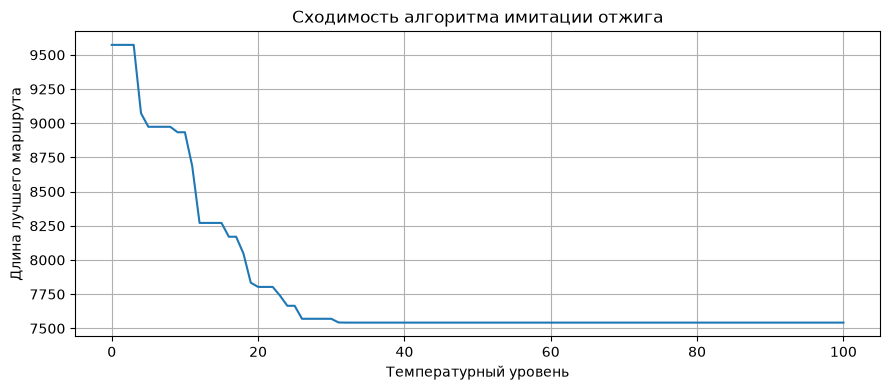

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,4))
plt.plot(range(len(history)), history)

plt.xlabel("Температурный уровень")
plt.ylabel("Длина лучшего маршрута")
plt.title("Сходимость алгоритма имитации отжига")
plt.grid()
plt.tight_layout()
plt.show()

### Статистические эксперименты

Для каждого из трёх тестов выполним **20 независимых запусков** с разными начальным городом и состоянием генератора случайных чисел. В рамках одного запуска все три алгоритма начинают с одного и того же маршрута ближайшего соседа. Для каждого метода сравним **минимум, среднее, стандартное отклонение, время работы** и отклонение от опубликованного оптимума:

$$\operatorname{gap}=\frac{F-OPT}{OPT}\cdot100\%. $$

Настройки отжига берём из ячейки выше: $T_0$, $\alpha$, $L$, $K$ **не подбираются автоматически**.


In [8]:
import time
import pandas as pd

RUNS = 20
SEED = 2026

rows = []
best_sa = {}
for test_no, test_name in enumerate(TESTS):
    c = instances[test_name]["dist"]
    best_sa[test_name] = None

    for run in range(RUNS):
        rng = random.Random(SEED + test_no * 10000 + run)
        start = rng.randrange(len(c))

        t0 = time.perf_counter()
        initial = nearest_neighbor(c, start)
        nn_length = check_tour(initial, c)
        nn_time = time.perf_counter() - t0

        t0 = time.perf_counter()
        local_tour, local_length = local_descent(initial, c)
        local_time = time.perf_counter() - t0

        t0 = time.perf_counter()
        sa_tour, sa_length, sa_history = simulated_annealing(
            initial, c, rng, T0=T0, alpha=alpha, L=L, K=K
        )
        sa_time = time.perf_counter() - t0

        check_tour(local_tour, c, local_length)
        check_tour(sa_tour, c, sa_length)
        assert min(nn_length, local_length, sa_length) >= OPTIMUM[test_name]

        for method, value, elapsed in [
            ("Ближайший сосед", nn_length, nn_time),
            ("Локальный спуск 2-opt", local_length, local_time),
            ("Имитация отжига", sa_length, sa_time),
        ]:
            rows.append({"Тест": test_name, "Запуск": run + 1,
                         "Метод": method, "Длина": value, "Время, с": elapsed})

        if best_sa[test_name] is None or sa_length < best_sa[test_name]["length"]:
            best_sa[test_name] = {"tour": sa_tour.copy(), "length": sa_length,
                                  "history": sa_history.copy(), "initial": initial.copy()}






results = pd.DataFrame(rows)
summary = (results.groupby(["Тест", "Метод"], sort=False)
           .agg(Минимум=("Длина", "min"), Среднее=("Длина", "mean"),
                Ст_откл=("Длина", "std"), Макс=("Длина", "max"),
                Время_с=("Время, с", "mean"))
           .reset_index())
summary["OPT"] = summary["Тест"].map(OPTIMUM)
summary["Разрыв, %"] = 100 * (summary["Среднее"] - summary["OPT"]) / summary["OPT"]
summary["Попаданий в OPT"] = [
    int(((results["Тест"] == row["Тест"]) &
         (results["Метод"] == row["Метод"]) &
         (results["Длина"] == row["OPT"])).sum())
    for _, row in summary.iterrows()
]

print(f"Статистика по {RUNS} запускам каждого метода, параметры SA: "
      f"T0={T0}, alpha={alpha}, L={L}, K={K}")
print(summary.round({"Среднее": 1, "Ст_откл": 1,
                     "Время_с": 4, "Разрыв, %": 2}).to_string(index=False))


Статистика по 20 запускам каждого метода, параметры SA: T0=100.0, alpha=0.95, L=5000, K=100
    Тест                 Метод  Минимум  Среднее  Ст_откл  Макс  Время_с  OPT  Разрыв, %  Попаданий в OPT
   eil51       Ближайший сосед      482    517.2     24.9   552   0.0002  426      21.42                0
   eil51 Локальный спуск 2-opt      430    439.9      6.1   449   0.0034  426       3.26                0
   eil51       Имитация отжига      427    432.6      4.1   441   0.8255  426       1.54                0
berlin52       Ближайший сосед     8181   9340.5    504.8 10298   0.0003 7542      23.85                0
berlin52 Локальный спуск 2-opt     7711   7862.0    108.5  8026   0.0047 7542       4.24                0
berlin52       Имитация отжига     7542   7597.1     95.3  7848   0.7693 7542       0.73               14
    st70       Ближайший сосед      796    841.8     22.3   881   0.0004  675      24.70                0
    st70 Локальный спуск 2-opt      687    711.8     14.8   

### Визуализация результатов

Сравниваем разброс длин маршрутов по 20 запускам.


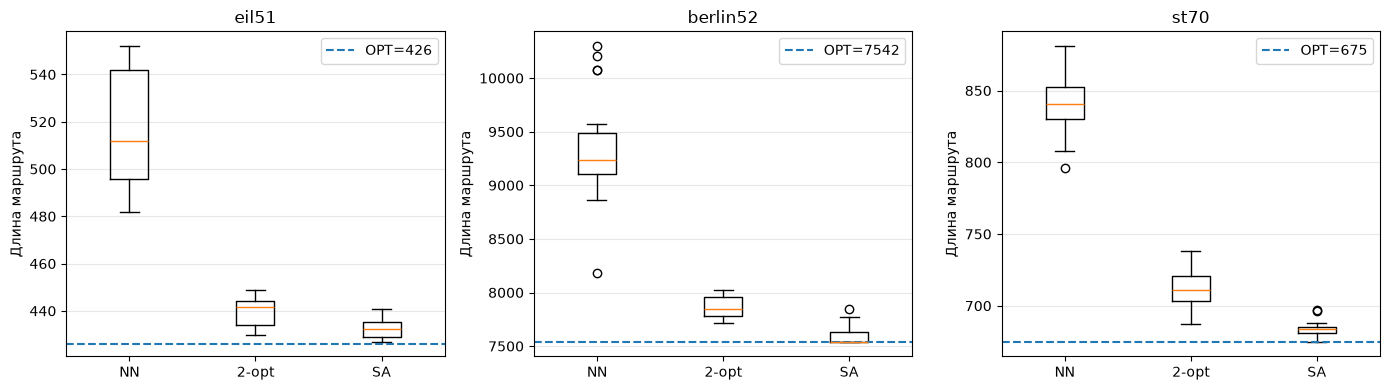

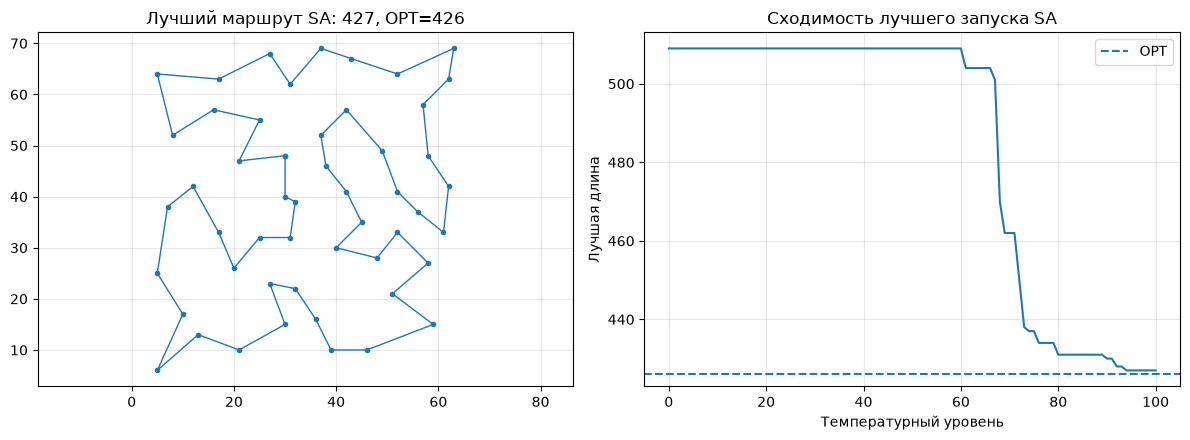

In [9]:
methods = ["Ближайший сосед", "Локальный спуск 2-opt", "Имитация отжига"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, test_name in zip(axes, TESTS):
    values = [results[(results["Тест"] == test_name) &
                      (results["Метод"] == method)]["Длина"].tolist()
              for method in methods]
    ax.boxplot(values, tick_labels=["NN", "2-opt", "SA"])
    ax.axhline(OPTIMUM[test_name], linestyle="--", label=f"OPT={OPTIMUM[test_name]}")
    ax.set_title(test_name)
    ax.set_ylabel("Длина маршрута")
    ax.legend()
    ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

# Маршрут лучшего запуска SA.
test_name = "eil51"
coords = instances[test_name]["coords"]
item = best_sa[test_name]
tour = item["tour"] + [item["tour"][0]]
xs = [coords[v][0] for v in tour]
ys = [coords[v][1] for v in tour]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(xs, ys, "-o", markersize=3, linewidth=1)
axes[0].set_title(f"Лучший маршрут SA: {item['length']}, OPT={OPTIMUM[test_name]}")
axes[0].set_aspect("equal", adjustable="datalim")
axes[0].grid(alpha=0.3)
axes[1].plot(range(len(item["history"])), item["history"])
axes[1].axhline(OPTIMUM[test_name], linestyle="--", label="OPT")
axes[1].set_title("Сходимость лучшего запуска SA")
axes[1].set_xlabel("Температурный уровень")
axes[1].set_ylabel("Лучшая длина")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()
